# Autoencoder Anomaly Detection: Feature Selection Comparison
## Full Features (119) vs Top 25 Selected Features

**Goal:** Retrain the autoencoder using only the top 25 most important features 
(treating all 16 `log_secbert_emb` dimensions as 1 feature, and all 16 `cmd_secbert_emb` dimensions as 1 feature),
then compare anomaly detection performance against the full-feature autoencoder.

**Data source:** `feature_selection_outputs2/` — contains the pre-processed feature matrix, labels, and SecBERT embeddings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, r2_score, mean_absolute_error)
from sklearn.manifold import TSNE
import warnings, os, json, time
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cpu
PyTorch: 2.9.1+cpu


## Part 2: Load Data from `feature_selection_outputs2/`

In [2]:
DATA_DIR = 'feature_selection_outputs2'

# Load feature matrix (119 features, no data leakage)
X_full_df = pd.read_parquet(f'{DATA_DIR}/feature_matrix_no_leakage.parquet')

# Load labels
labels_df = pd.read_parquet(f'{DATA_DIR}/labels.parquet')

# Load feature importance rankings
fi = pd.read_csv(f'{DATA_DIR}/feature_importance_malicious_detection.csv')
fi = fi.sort_values('Average_Score', ascending=False)

print(f"Feature matrix shape: {X_full_df.shape}")
print(f"Labels shape: {labels_df.shape}")
print(f"Columns in labels: {list(labels_df.columns)}")
print(f"\nClass distribution:")
print(labels_df['malicious'].value_counts())
print(f"\nBenign: {(labels_df['malicious']==0).sum():,}  |  Malicious: {(labels_df['malicious']==1).sum():,}")

Feature matrix shape: (115726, 119)
Labels shape: (115726, 3)
Columns in labels: ['malicious', 'cyber_kill_chain_tactic', 'ckc_encoded']

Class distribution:
malicious
0    90308
1    25418
Name: count, dtype: int64

Benign: 90,308  |  Malicious: 25,418


## Part 3: Identify Top 25 Features (SecBERT Embeddings = 1 Feature Each)

**Rule:** All 16 `log_secbert_emb_*` dimensions count as **1 feature**, 
and all 16 `cmd_secbert_emb_*` dimensions count as **1 feature**.
So we need 23 more individual features to reach 25.

In [3]:
# Separate embedding features from individual features
log_secbert_cols = [c for c in X_full_df.columns if c.startswith('log_secbert_emb_')]
cmd_secbert_cols = [c for c in X_full_df.columns if c.startswith('cmd_secbert_emb_')]
individual_cols  = [c for c in X_full_df.columns if c not in log_secbert_cols + cmd_secbert_cols]

# Rank individual features by their Average_Score
fi_individual = fi[~fi['Feature'].str.startswith(('log_secbert_emb_', 'cmd_secbert_emb_'))]
fi_individual = fi_individual.sort_values('Average_Score', ascending=False)

# Compute average importance of each embedding group
log_secbert_avg = fi[fi['Feature'].str.startswith('log_secbert_emb_')]['Average_Score'].mean()
cmd_secbert_avg = fi[fi['Feature'].str.startswith('cmd_secbert_emb_')]['Average_Score'].mean()

print("="*70)
print("FEATURE GROUP IMPORTANCE")
print("="*70)
print(f"log_secbert_emb (16 dims) — avg importance: {log_secbert_avg:.6f}")
print(f"cmd_secbert_emb (16 dims) — avg importance: {cmd_secbert_avg:.6f}")
print(f"\nTop individual features:")
print(fi_individual[['Feature', 'Average_Score']].head(25).to_string(index=False))

# Build the top 25 conceptual features:
# 1. log_secbert_emb (group of 16) — highest avg importance
# 2. cmd_secbert_emb (group of 16) — mid-range importance
# 3-25. Top 23 individual features
N_INDIVIDUAL = 23
top_individual_features = fi_individual['Feature'].head(N_INDIVIDUAL).tolist()

# Final selected columns (actual column names)
selected_columns = top_individual_features + log_secbert_cols + cmd_secbert_cols

print(f"\n{'='*70}")
print(f"TOP 25 FEATURES (conceptual) → {len(selected_columns)} actual columns")
print(f"{'='*70}")
print(f"  • log_secbert_emb (16 dims) = 1 feature")
print(f"  • cmd_secbert_emb (16 dims) = 1 feature")
print(f"  • {N_INDIVIDUAL} individual features")
print(f"  → Total actual columns: {len(selected_columns)}")
print(f"\nSelected individual features:")
for i, f_name in enumerate(top_individual_features, 1):
    score = fi_individual[fi_individual['Feature'] == f_name]['Average_Score'].values[0]
    print(f"  {i:2d}. {f_name:<45} (score: {score:.6f})")

FEATURE GROUP IMPORTANCE
log_secbert_emb (16 dims) — avg importance: 0.207366
cmd_secbert_emb (16 dims) — avg importance: 0.024805

Top individual features:
                             Feature  Average_Score
                      decoder_auditd       0.536174
                          firedtimes       0.357669
   location__var_log_audit_audit.log       0.268126
                    srcip_is_private       0.171310
               decoder_web-accesslog       0.159482
location__var_log_apache2_access.log       0.157999
                      firedtimes_log       0.147013
                     path_is_missing       0.098405
                             has_md5       0.090567
                          cmd_length       0.088394
                          has_sha256       0.087528
                      syscheck_added       0.080821
                      cmd_is_missing       0.074680
                decoder_dpkg-decoder       0.046992
                    syscheck_deleted       0.038714
           

## Part 4: Build Full vs Reduced Feature Matrices + Scale & Split

In [4]:
# Full feature matrix (all 119 features)
X_full = X_full_df.values.astype(np.float32)

# Reduced feature matrix (top 25 conceptual = 55 actual columns)
X_reduced_df = X_full_df[selected_columns]
X_reduced = X_reduced_df.values.astype(np.float32)

# Labels
y_malicious = labels_df['malicious'].values
y_ckc = labels_df['ckc_encoded'].values

print("="*70)
print("FEATURE MATRIX COMPARISON")
print("="*70)
print(f"Full feature matrix:    {X_full.shape} → {X_full.shape[1]} input dims")
print(f"Reduced feature matrix: {X_reduced.shape} → {X_reduced.shape[1]} input dims")
print(f"Reduction: {X_full.shape[1]} → {X_reduced.shape[1]} ({100*(1-X_reduced.shape[1]/X_full.shape[1]):.1f}% fewer columns)")
print(f"\nSamples: {X_full.shape[0]:,}")
print(f"Malicious: {(y_malicious==1).sum():,} ({(y_malicious==1).mean()*100:.1f}%)")
print(f"Benign:    {(y_malicious==0).sum():,} ({(y_malicious==0).mean()*100:.1f}%)")

# Scale both matrices
scaler_full = StandardScaler()
scaler_reduced = StandardScaler()

X_full_scaled = scaler_full.fit_transform(X_full).astype(np.float32)
X_reduced_scaled = scaler_reduced.fit_transform(X_reduced).astype(np.float32)

# Split for ANOMALY DETECTION: train on benign only
benign_mask = y_malicious == 0

X_full_benign = X_full_scaled[benign_mask]
X_train_full, X_val_full = train_test_split(X_full_benign, test_size=0.2, random_state=42)

X_reduced_benign = X_reduced_scaled[benign_mask]
X_train_reduced, X_val_reduced = train_test_split(X_reduced_benign, test_size=0.2, random_state=42)

print(f"\n{'='*70}")
print(f"DATA SPLITS (Benign-Only Training for Anomaly Detection)")
print(f"{'='*70}")
print(f"{'Split':<25} {'Full Features':>15} {'Reduced Features':>18}")
print("-"*60)
print(f"{'Train (benign)':<25} {X_train_full.shape[0]:>15,} {X_train_reduced.shape[0]:>18,}")
print(f"{'Validation (benign)':<25} {X_val_full.shape[0]:>15,} {X_val_reduced.shape[0]:>18,}")
print(f"{'Test (all data)':<25} {X_full_scaled.shape[0]:>15,} {X_reduced_scaled.shape[0]:>18,}")

FEATURE MATRIX COMPARISON
Full feature matrix:    (115726, 119) → 119 input dims
Reduced feature matrix: (115726, 55) → 55 input dims
Reduction: 119 → 55 (53.8% fewer columns)

Samples: 115,726
Malicious: 25,418 (22.0%)
Benign:    90,308 (78.0%)

DATA SPLITS (Benign-Only Training for Anomaly Detection)
Split                       Full Features   Reduced Features
------------------------------------------------------------
Train (benign)                     72,246             72,246
Validation (benign)                18,062             18,062
Test (all data)                   115,726            115,726


## Part 5: Autoencoder Architectures + Training Functions

In [5]:
class SIEMAutoencoder(nn.Module):
    """Standard Autoencoder: input → 256 → 128 → 64 → 128 → 256 → input"""
    
    def __init__(self, input_dim, latent_dim=64, dropout_rate=0.2):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, latent_dim), nn.BatchNorm1d(latent_dim), nn.LeakyReLU(0.2),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, input_dim),
        )
        self._init_weights()
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    
    def encode(self, x): return self.encoder(x)
    def decode(self, z): return self.decoder(z)
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class RegularizedAutoencoder(nn.Module):
    """VAE-style AE with mu/logvar heads and learnable center."""
    
    def __init__(self, input_dim, latent_dim=64, dropout_rate=0.2):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        self.encoder_body = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
        )
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, input_dim),
        )
        self.center = nn.Parameter(torch.zeros(latent_dim))
        self._init_weights()
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    
    def encode(self, x):
        h = self.encoder_body(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std) if self.training else mu
        return z, mu, logvar
    
    def forward(self, x):
        z, mu, logvar = self.encode(x)
        return self.decoder(z), z, mu, logvar


# Compare architectures
input_dim_full = X_full_scaled.shape[1]
input_dim_reduced = X_reduced_scaled.shape[1]
latent_dim = 64

model_full_test = SIEMAutoencoder(input_dim_full, latent_dim)
model_reduced_test = SIEMAutoencoder(input_dim_reduced, latent_dim)

params_full = sum(p.numel() for p in model_full_test.parameters())
params_reduced = sum(p.numel() for p in model_reduced_test.parameters())

print("="*70)
print("MODEL ARCHITECTURE COMPARISON")
print("="*70)
print(f"{'Metric':<30} {'Full Features':>15} {'Reduced Features':>18}")
print("-"*65)
print(f"{'Input dimension':<30} {input_dim_full:>15} {input_dim_reduced:>18}")
print(f"{'Latent dimension':<30} {latent_dim:>15} {latent_dim:>18}")
print(f"{'Total parameters':<30} {params_full:>15,} {params_reduced:>18,}")
print(f"{'Compression ratio':<30} {input_dim_full/latent_dim:>15.1f}x {input_dim_reduced/latent_dim:>18.1f}x")
print(f"{'Parameter reduction':<30} {'':>15} {100*(1-params_reduced/params_full):>17.1f}%")

del model_full_test, model_reduced_test

MODEL ARCHITECTURE COMPARISON
Metric                           Full Features   Reduced Features
-----------------------------------------------------------------
Input dimension                            119                 55
Latent dimension                            64                 64
Total parameters                       145,463            112,631
Compression ratio                          1.9x                0.9x
Parameter reduction                                         22.6%


In [6]:
def create_dataloader(X, batch_size=256, shuffle=True):
    tensor = torch.FloatTensor(X)
    return DataLoader(TensorDataset(tensor, tensor), batch_size=batch_size, shuffle=shuffle)


def train_standard_ae(model, train_loader, val_loader, epochs=100, lr=1e-3,
                      weight_decay=1e-5, patience=15, device='cpu'):
    """Train standard autoencoder with MSE loss."""
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': [], 'lr': []}
    best_val_loss = float('inf')
    best_state = None
    patience_ctr = 0
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for bx, _ in train_loader:
            bx = bx.to(device)
            x_hat, _ = model(bx)
            loss = criterion(x_hat, bx)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * bx.size(0)
        train_loss /= len(train_loader.dataset)
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device)
                x_hat, _ = model(bx)
                val_loss += criterion(x_hat, bx).item() * bx.size(0)
        val_loss /= len(val_loader.dataset)
        
        scheduler.step(val_loss)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['lr'].append(optimizer.param_groups[0]['lr'])
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {train_loss:.6f} | Val: {val_loss:.6f} | LR: {optimizer.param_groups[0]['lr']:.2e}")
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val_loss:.6f}")
    return history


def compute_center_loss(z, center):
    return ((z - center) ** 2).sum(dim=1).mean()


def train_regularized_ae(model, train_loader, val_loader, epochs=100, lr=1e-3,
                         weight_decay=1e-5, patience=15, beta=1e-3, gamma=1e-2,
                         warmup_frac=0.2, device='cpu'):
    """Train regularized autoencoder with MSE + KL + Center loss."""
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_total': [], 'train_recon': [], 'train_kl': [], 'train_center': [],
               'val_total': [], 'val_recon': [], 'val_kl': [], 'val_center': [],
               'lr': [], 'beta_eff': []}
    best_val = float('inf'); best_state = None; patience_ctr = 0
    warmup_epochs = int(epochs * warmup_frac)
    
    for epoch in range(epochs):
        beta_eff = beta * min(1.0, (epoch + 1) / max(warmup_epochs, 1))
        
        model.train()
        e_r = e_k = e_c = 0.0; n = 0
        for bx, _ in train_loader:
            bx = bx.to(device); bs = bx.size(0)
            x_hat, z, mu, logvar = model(bx)
            l_r = criterion(x_hat, bx)
            l_k = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
            l_c = compute_center_loss(z, model.center) if gamma > 0 else torch.tensor(0.0)
            loss = l_r + beta_eff * l_k + gamma * l_c
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            e_r += l_r.item()*bs; e_k += l_k.item()*bs; e_c += l_c.item()*bs; n += bs
        e_r /= n; e_k /= n; e_c /= n; e_t = e_r + beta_eff * e_k + gamma * e_c
        
        model.eval()
        vr = vk = vc = 0.0; nv = 0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device); bs = bx.size(0)
                x_hat, z, mu, logvar = model(bx)
                vr += criterion(x_hat, bx).item()*bs
                vk += (-0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())).item()*bs
                vc += (compute_center_loss(z, model.center).item()*bs if gamma > 0 else 0.0)
                nv += bs
        vr /= nv; vk /= nv; vc /= nv; vt = vr + beta_eff * vk + gamma * vc
        
        scheduler.step(vt)
        history['train_total'].append(e_t); history['train_recon'].append(e_r)
        history['train_kl'].append(e_k); history['train_center'].append(e_c)
        history['val_total'].append(vt); history['val_recon'].append(vr)
        history['val_kl'].append(vk); history['val_center'].append(vc)
        history['lr'].append(optimizer.param_groups[0]['lr'])
        history['beta_eff'].append(beta_eff)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Ep {epoch+1:3d}/{epochs} B={beta_eff:.1e} recon={e_r:.6f} kl={e_k:.4f} total={e_t:.6f} val={vt:.6f}")
        
        if vt < best_val:
            best_val = vt; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val total loss: {best_val:.6f}")
    return history


def compute_anomaly_scores_standard(model, X, device='cpu'):
    model.eval()
    scores = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=256, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            x_hat, _ = model(bx)
            mse = ((x_hat - bx)**2).mean(dim=1)
            scores.append(mse.cpu().numpy())
    return np.concatenate(scores)


def compute_anomaly_scores_regularized(model, X, beta=1e-3, device='cpu'):
    model.eval()
    scores = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=256, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            x_hat, z, mu, logvar = model(bx)
            mse = ((x_hat - bx)**2).mean(dim=1)
            kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).mean(dim=1)
            scores.append((mse + beta * kl).cpu().numpy())
    return np.concatenate(scores)


def find_threshold_youden(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    j = tpr - fpr
    return thresholds[np.argmax(j)]


def evaluate_model_metrics(y_true, scores, threshold):
    preds = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    return {
        'ROC-AUC': roc_auc_score(y_true, scores),
        'AP': average_precision_score(y_true, scores),
        'Balanced Acc': balanced_accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall': recall_score(y_true, preds, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
        'F1': f1_score(y_true, preds, zero_division=0),
        'Threshold': threshold,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    }


def get_latent_vectors(model, X, is_regularized=False, device='cpu'):
    model.eval()
    latents = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=256, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            if is_regularized:
                _, z, _, _ = model(bx)
            else:
                _, z = model(bx)
            latents.append(z.cpu().numpy())
    return np.concatenate(latents)


print("All model classes and training/evaluation functions defined.")

All model classes and training/evaluation functions defined.


## Part 6: Train Standard AE — Full Features (119 dims)

In [7]:
print("="*70)
print("TRAINING: Standard AE on FULL features (benign-only)")
print("="*70)

train_loader_full = create_dataloader(X_train_full, batch_size=256, shuffle=True)
val_loader_full = create_dataloader(X_val_full, batch_size=256, shuffle=False)

model_ae_full = SIEMAutoencoder(input_dim=input_dim_full, latent_dim=64, dropout_rate=0.2).to(device)
print(f"Input dim: {input_dim_full} | Parameters: {sum(p.numel() for p in model_ae_full.parameters()):,}\n")

t0 = time.time()
history_ae_full = train_standard_ae(model_ae_full, train_loader_full, val_loader_full,
                                     epochs=100, lr=1e-3, patience=15, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Standard AE on FULL features (benign-only)
Input dim: 119 | Parameters: 145,463

  Epoch [  1/100] Train: 0.344327 | Val: 0.101812 | LR: 1.00e-03
  Epoch [ 10/100] Train: 0.049218 | Val: 0.035273 | LR: 1.00e-03
  Epoch [ 20/100] Train: 0.039788 | Val: 0.033055 | LR: 1.00e-03
  Epoch [ 30/100] Train: 0.035601 | Val: 0.036263 | LR: 5.00e-04
  Epoch [ 40/100] Train: 0.032511 | Val: 0.023454 | LR: 2.50e-04
  Epoch [ 50/100] Train: 0.031411 | Val: 0.017878 | LR: 2.50e-04
  Epoch [ 60/100] Train: 0.031459 | Val: 0.022198 | LR: 1.25e-04
  Epoch [ 70/100] Train: 0.030274 | Val: 0.020903 | LR: 6.25e-05
  Epoch [ 80/100] Train: 0.030237 | Val: 0.015989 | LR: 6.25e-05
  Epoch [ 90/100] Train: 0.029962 | Val: 0.015300 | LR: 1.56e-05
  Early stop at epoch 91
  Best val loss: 0.014047
Training time: 13.4 min


## Part 7: Train Standard AE — Reduced Features (Top 25)

In [8]:
print("="*70)
print("TRAINING: Standard AE on REDUCED features (benign-only)")
print("="*70)

train_loader_reduced = create_dataloader(X_train_reduced, batch_size=256, shuffle=True)
val_loader_reduced = create_dataloader(X_val_reduced, batch_size=256, shuffle=False)

model_ae_reduced = SIEMAutoencoder(input_dim=input_dim_reduced, latent_dim=64, dropout_rate=0.2).to(device)
print(f"Input dim: {input_dim_reduced} | Parameters: {sum(p.numel() for p in model_ae_reduced.parameters()):,}\n")

t0 = time.time()
history_ae_reduced = train_standard_ae(model_ae_reduced, train_loader_reduced, val_loader_reduced,
                                        epochs=100, lr=1e-3, patience=15, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Standard AE on REDUCED features (benign-only)
Input dim: 55 | Parameters: 112,631

  Epoch [  1/100] Train: 0.242223 | Val: 0.038465 | LR: 1.00e-03
  Epoch [ 10/100] Train: 0.035227 | Val: 0.009736 | LR: 1.00e-03
  Epoch [ 20/100] Train: 0.027415 | Val: 0.007905 | LR: 1.00e-03
  Epoch [ 30/100] Train: 0.024981 | Val: 0.006185 | LR: 1.00e-03
  Epoch [ 40/100] Train: 0.023541 | Val: 0.005658 | LR: 1.00e-03
  Epoch [ 50/100] Train: 0.021911 | Val: 0.005216 | LR: 5.00e-04
  Epoch [ 60/100] Train: 0.021301 | Val: 0.004967 | LR: 2.50e-04
  Epoch [ 70/100] Train: 0.021226 | Val: 0.009734 | LR: 1.25e-04
  Epoch [ 80/100] Train: 0.020856 | Val: 0.004533 | LR: 6.25e-05
  Epoch [ 90/100] Train: 0.020795 | Val: 0.010357 | LR: 3.13e-05
  Epoch [100/100] Train: 0.020872 | Val: 0.005615 | LR: 1.56e-05
  Best val loss: 0.004364
Training time: 10.0 min


## Part 8: Train Regularized AE (KL + Center) — Full Features

In [9]:
print("="*70)
print("TRAINING: Regularized AE on FULL features (beta=1e-3, gamma=1e-2)")
print("="*70)

model_reg_full = RegularizedAutoencoder(input_dim=input_dim_full, latent_dim=64, dropout_rate=0.2).to(device)
print(f"Input dim: {input_dim_full} | Parameters: {sum(p.numel() for p in model_reg_full.parameters()):,}\n")

t0 = time.time()
history_reg_full = train_regularized_ae(model_reg_full, train_loader_full, val_loader_full,
                                         epochs=100, lr=1e-3, patience=15,
                                         beta=1e-3, gamma=1e-2, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Regularized AE on FULL features (beta=1e-3, gamma=1e-2)
Input dim: 119 | Parameters: 153,655

  Ep   1/100 B=5.0e-05 recon=0.473414 kl=12095.9681 total=5341.585898 val=0.150026
  Ep  10/100 B=5.0e-04 recon=0.058061 kl=4.0708 total=0.066483 val=0.062368
  Ep  20/100 B=1.0e-03 recon=0.044358 kl=4.3425 total=0.052006 val=0.063310
  Ep  30/100 B=1.0e-03 recon=0.039533 kl=4.5467 total=0.046455 val=0.060904
  Ep  40/100 B=1.0e-03 recon=0.037463 kl=4.7229 total=0.043963 val=0.041728
  Ep  50/100 B=1.0e-03 recon=0.036710 kl=4.8280 total=0.043047 val=0.040423
  Early stop at epoch 59
  Best val total loss: 0.032141
Training time: 6.3 min


## Part 9: Train Regularized AE (KL + Center) — Reduced Features

In [10]:
print("="*70)
print("TRAINING: Regularized AE on REDUCED features (beta=1e-3, gamma=1e-2)")
print("="*70)

model_reg_reduced = RegularizedAutoencoder(input_dim=input_dim_reduced, latent_dim=64, dropout_rate=0.2).to(device)
print(f"Input dim: {input_dim_reduced} | Parameters: {sum(p.numel() for p in model_reg_reduced.parameters()):,}\n")

t0 = time.time()
history_reg_reduced = train_regularized_ae(model_reg_reduced, train_loader_reduced, val_loader_reduced,
                                            epochs=100, lr=1e-3, patience=15,
                                            beta=1e-3, gamma=1e-2, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Regularized AE on REDUCED features (beta=1e-3, gamma=1e-2)
Input dim: 55 | Parameters: 120,823

  Ep   1/100 B=5.0e-05 recon=0.331507 kl=1.1168 total=0.713699 val=0.075758
  Ep  10/100 B=5.0e-04 recon=0.038919 kl=4.3648 total=0.045321 val=0.017135
  Ep  20/100 B=1.0e-03 recon=0.030540 kl=4.3979 total=0.037196 val=0.014282
  Ep  30/100 B=1.0e-03 recon=0.028689 kl=4.4548 total=0.035029 val=0.012672
  Ep  40/100 B=1.0e-03 recon=0.026190 kl=4.5676 total=0.032177 val=0.011780
  Ep  50/100 B=1.0e-03 recon=0.025435 kl=4.6015 total=0.031290 val=0.011452
  Ep  60/100 B=1.0e-03 recon=0.024770 kl=4.6495 total=0.030481 val=0.010931
  Ep  70/100 B=1.0e-03 recon=0.024672 kl=4.6872 total=0.030338 val=0.010783
  Ep  80/100 B=1.0e-03 recon=0.024144 kl=4.7240 total=0.029745 val=0.010611
  Ep  90/100 B=1.0e-03 recon=0.023985 kl=4.7501 total=0.029575 val=0.010678
  Ep 100/100 B=1.0e-03 recon=0.024161 kl=4.7702 total=0.029737 val=0.010985
  Best val total loss: 0.010170
Training time: 10.7 min


## Part 10: Evaluate All 4 Models — Anomaly Detection Metrics

In [11]:
print("="*70)
print("COMPUTING ANOMALY SCORES ON ALL DATA")
print("="*70)

# Standard AE scores
scores_ae_full = compute_anomaly_scores_standard(model_ae_full, X_full_scaled, device)
scores_ae_reduced = compute_anomaly_scores_standard(model_ae_reduced, X_reduced_scaled, device)

# Regularized AE scores
scores_reg_full = compute_anomaly_scores_regularized(model_reg_full, X_full_scaled, beta=1e-3, device=device)
scores_reg_reduced = compute_anomaly_scores_regularized(model_reg_reduced, X_reduced_scaled, beta=1e-3, device=device)

# Find optimal thresholds
th_ae_full = find_threshold_youden(y_malicious, scores_ae_full)
th_ae_reduced = find_threshold_youden(y_malicious, scores_ae_reduced)
th_reg_full = find_threshold_youden(y_malicious, scores_reg_full)
th_reg_reduced = find_threshold_youden(y_malicious, scores_reg_reduced)

# Evaluate
metrics_ae_full = evaluate_model_metrics(y_malicious, scores_ae_full, th_ae_full)
metrics_ae_reduced = evaluate_model_metrics(y_malicious, scores_ae_reduced, th_ae_reduced)
metrics_reg_full = evaluate_model_metrics(y_malicious, scores_reg_full, th_reg_full)
metrics_reg_reduced = evaluate_model_metrics(y_malicious, scores_reg_reduced, th_reg_reduced)

# Build comparison table
all_results = {
    'Standard AE (Full 119)': metrics_ae_full,
    'Standard AE (Top 25)': metrics_ae_reduced,
    'Regularized AE (Full 119)': metrics_reg_full,
    'Regularized AE (Top 25)': metrics_reg_reduced,
}

print(f"\n{'='*110}")
print(f"{'ANOMALY DETECTION RESULTS':^110}")
print(f"{'='*110}")
print(f"{'Model':<30} {'ROC-AUC':>8} {'AP':>8} {'Bal.Acc':>8} {'Prec':>7} {'Recall':>7} {'Spec':>7} {'F1':>7} {'TP':>6} {'FP':>6} {'FN':>6} {'TN':>6}")
print("-"*110)
for name, m in all_results.items():
    print(f"{name:<30} {m['ROC-AUC']:>8.4f} {m['AP']:>8.4f} {m['Balanced Acc']:>8.4f} "
          f"{m['Precision']:>7.4f} {m['Recall']:>7.4f} {m['Specificity']:>7.4f} {m['F1']:>7.4f} "
          f"{m['TP']:>6} {m['FP']:>6} {m['FN']:>6} {m['TN']:>6}")
print("="*110)

# Highlight improvement
delta_roc_ae = metrics_ae_reduced['ROC-AUC'] - metrics_ae_full['ROC-AUC']
delta_roc_reg = metrics_reg_reduced['ROC-AUC'] - metrics_reg_full['ROC-AUC']
delta_f1_ae = metrics_ae_reduced['F1'] - metrics_ae_full['F1']
delta_f1_reg = metrics_reg_reduced['F1'] - metrics_reg_full['F1']

print(f"\n{'IMPROVEMENT WITH FEATURE SELECTION':^70}")
print("-"*70)
print(f"Standard AE:     ROC-AUC delta = {delta_roc_ae:+.4f}  |  F1 delta = {delta_f1_ae:+.4f}")
print(f"Regularized AE:  ROC-AUC delta = {delta_roc_reg:+.4f}  |  F1 delta = {delta_f1_reg:+.4f}")

if delta_roc_ae > 0:
    print(f"\n>>> Feature selection IMPROVED Standard AE by {delta_roc_ae:+.4f} ROC-AUC")
else:
    print(f"\n>>> Feature selection changed Standard AE by {delta_roc_ae:+.4f} ROC-AUC")

if delta_roc_reg > 0:
    print(f">>> Feature selection IMPROVED Regularized AE by {delta_roc_reg:+.4f} ROC-AUC")
else:
    print(f">>> Feature selection changed Regularized AE by {delta_roc_reg:+.4f} ROC-AUC")

COMPUTING ANOMALY SCORES ON ALL DATA

                                          ANOMALY DETECTION RESULTS                                           
Model                           ROC-AUC       AP  Bal.Acc    Prec  Recall    Spec      F1     TP     FP     FN     TN
--------------------------------------------------------------------------------------------------------------
Standard AE (Full 119)           0.9752   0.9109   0.9314  0.7660  0.9440  0.9188  0.8457  23995   7332   1423  82976
Standard AE (Top 25)             0.9821   0.9491   0.9370  0.7893  0.9450  0.9290  0.8602  24021   6412   1397  83896
Regularized AE (Full 119)        0.9773   0.9093   0.9378  0.7659  0.9580  0.9176  0.8513  24351   7443   1067  82865
Regularized AE (Top 25)          0.9849   0.9553   0.9452  0.8034  0.9562  0.9341  0.8732  24304   5947   1114  84361

                  IMPROVEMENT WITH FEATURE SELECTION                  
----------------------------------------------------------------------
Standar

## Part 11: Training Loss Curves Comparison

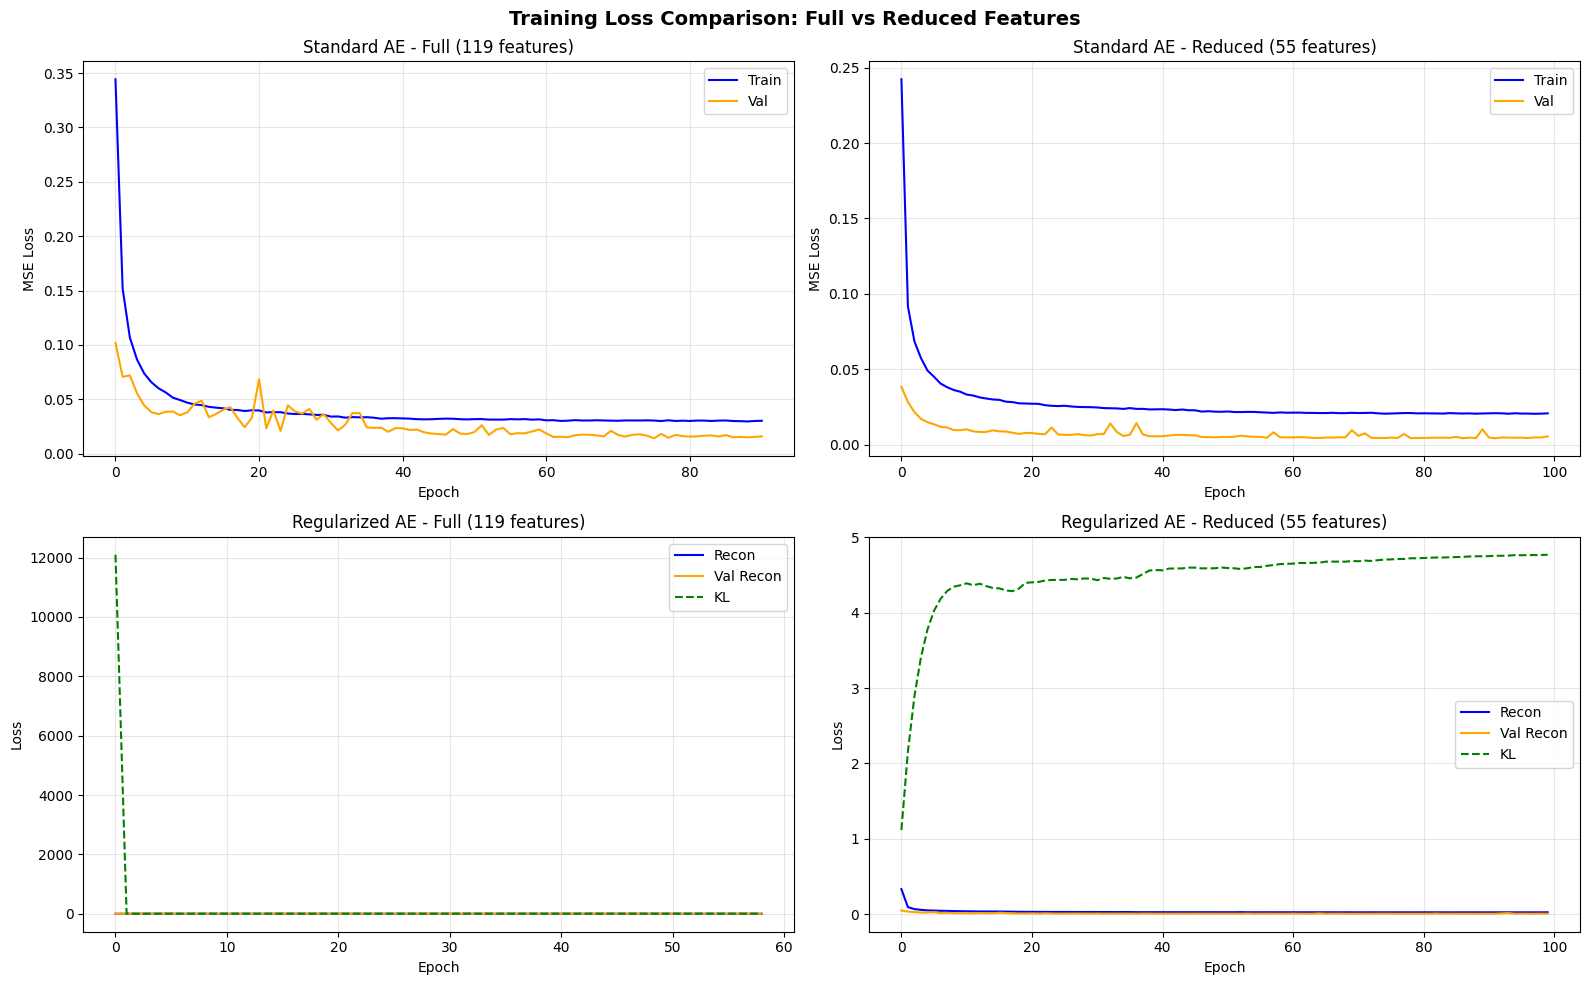

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Training Loss Comparison: Full vs Reduced Features', fontsize=14, fontweight='bold')

# Standard AE - Full
axes[0,0].plot(history_ae_full['train_loss'], label='Train', color='blue')
axes[0,0].plot(history_ae_full['val_loss'], label='Val', color='orange')
axes[0,0].set_title(f'Standard AE - Full ({input_dim_full} features)')
axes[0,0].set_xlabel('Epoch'); axes[0,0].set_ylabel('MSE Loss')
axes[0,0].legend(); axes[0,0].grid(True, alpha=0.3)

# Standard AE - Reduced
axes[0,1].plot(history_ae_reduced['train_loss'], label='Train', color='blue')
axes[0,1].plot(history_ae_reduced['val_loss'], label='Val', color='orange')
axes[0,1].set_title(f'Standard AE - Reduced ({input_dim_reduced} features)')
axes[0,1].set_xlabel('Epoch'); axes[0,1].set_ylabel('MSE Loss')
axes[0,1].legend(); axes[0,1].grid(True, alpha=0.3)

# Regularized AE - Full
axes[1,0].plot(history_reg_full['train_recon'], label='Recon', color='blue')
axes[1,0].plot(history_reg_full['val_recon'], label='Val Recon', color='orange')
axes[1,0].plot(history_reg_full['train_kl'], label='KL', color='green', linestyle='--')
axes[1,0].set_title(f'Regularized AE - Full ({input_dim_full} features)')
axes[1,0].set_xlabel('Epoch'); axes[1,0].set_ylabel('Loss')
axes[1,0].legend(); axes[1,0].grid(True, alpha=0.3)

# Regularized AE - Reduced
axes[1,1].plot(history_reg_reduced['train_recon'], label='Recon', color='blue')
axes[1,1].plot(history_reg_reduced['val_recon'], label='Val Recon', color='orange')
axes[1,1].plot(history_reg_reduced['train_kl'], label='KL', color='green', linestyle='--')
axes[1,1].set_title(f'Regularized AE - Reduced ({input_dim_reduced} features)')
axes[1,1].set_xlabel('Epoch'); axes[1,1].set_ylabel('Loss')
axes[1,1].legend(); axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/feature_selection_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 12: ROC & Precision-Recall Curve Comparison

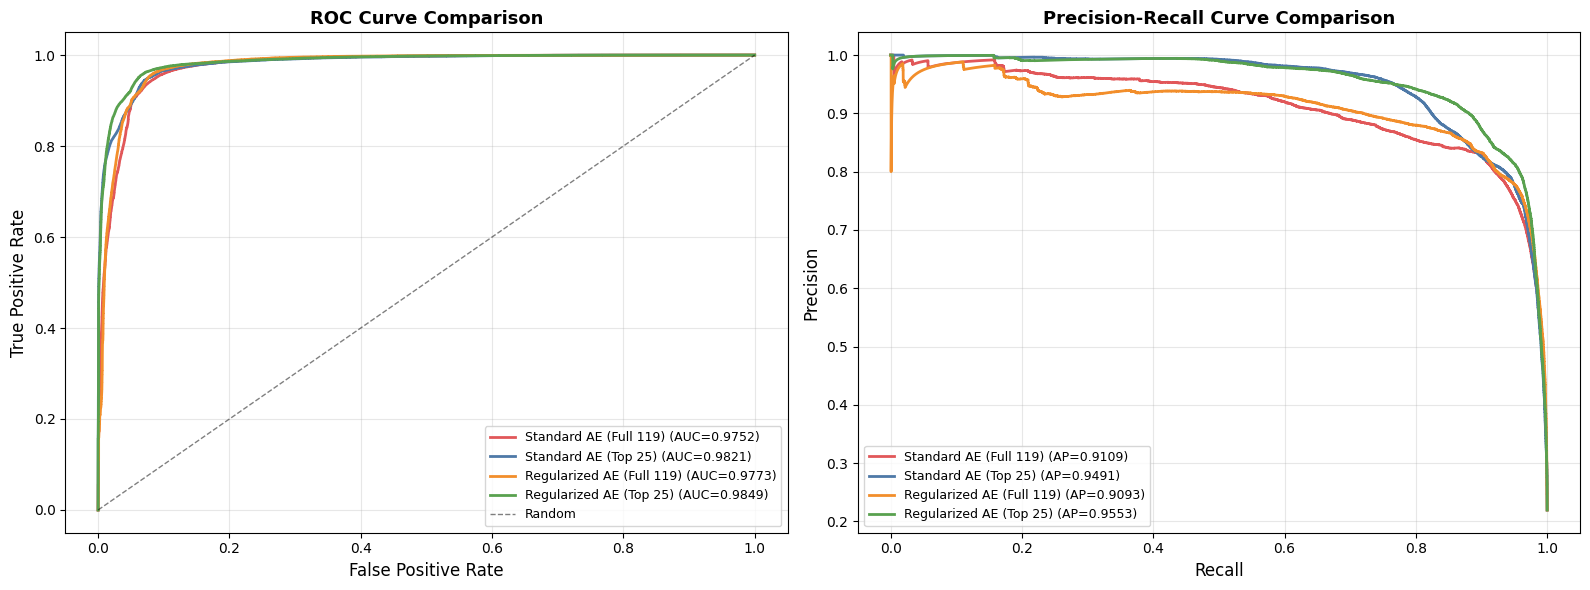

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#e15759', '#4e79a7', '#f28e2b', '#59a14f']
labels_names = list(all_results.keys())
all_scores = [scores_ae_full, scores_ae_reduced, scores_reg_full, scores_reg_reduced]

# ROC Curves
for i, (name, scores) in enumerate(zip(labels_names, all_scores)):
    fpr, tpr, _ = roc_curve(y_malicious, scores)
    auc_val = roc_auc_score(y_malicious, scores)
    axes[0].plot(fpr, tpr, color=colors[i], lw=2, label=f'{name} (AUC={auc_val:.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Random')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('ROC Curve Comparison', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curves
for i, (name, scores) in enumerate(zip(labels_names, all_scores)):
    prec, rec, _ = precision_recall_curve(y_malicious, scores)
    ap = average_precision_score(y_malicious, scores)
    axes[1].plot(rec, prec, color=colors[i], lw=2, label=f'{name} (AP={ap:.4f})')

axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision-Recall Curve Comparison', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/feature_selection_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 13: Confusion Matrix Comparison

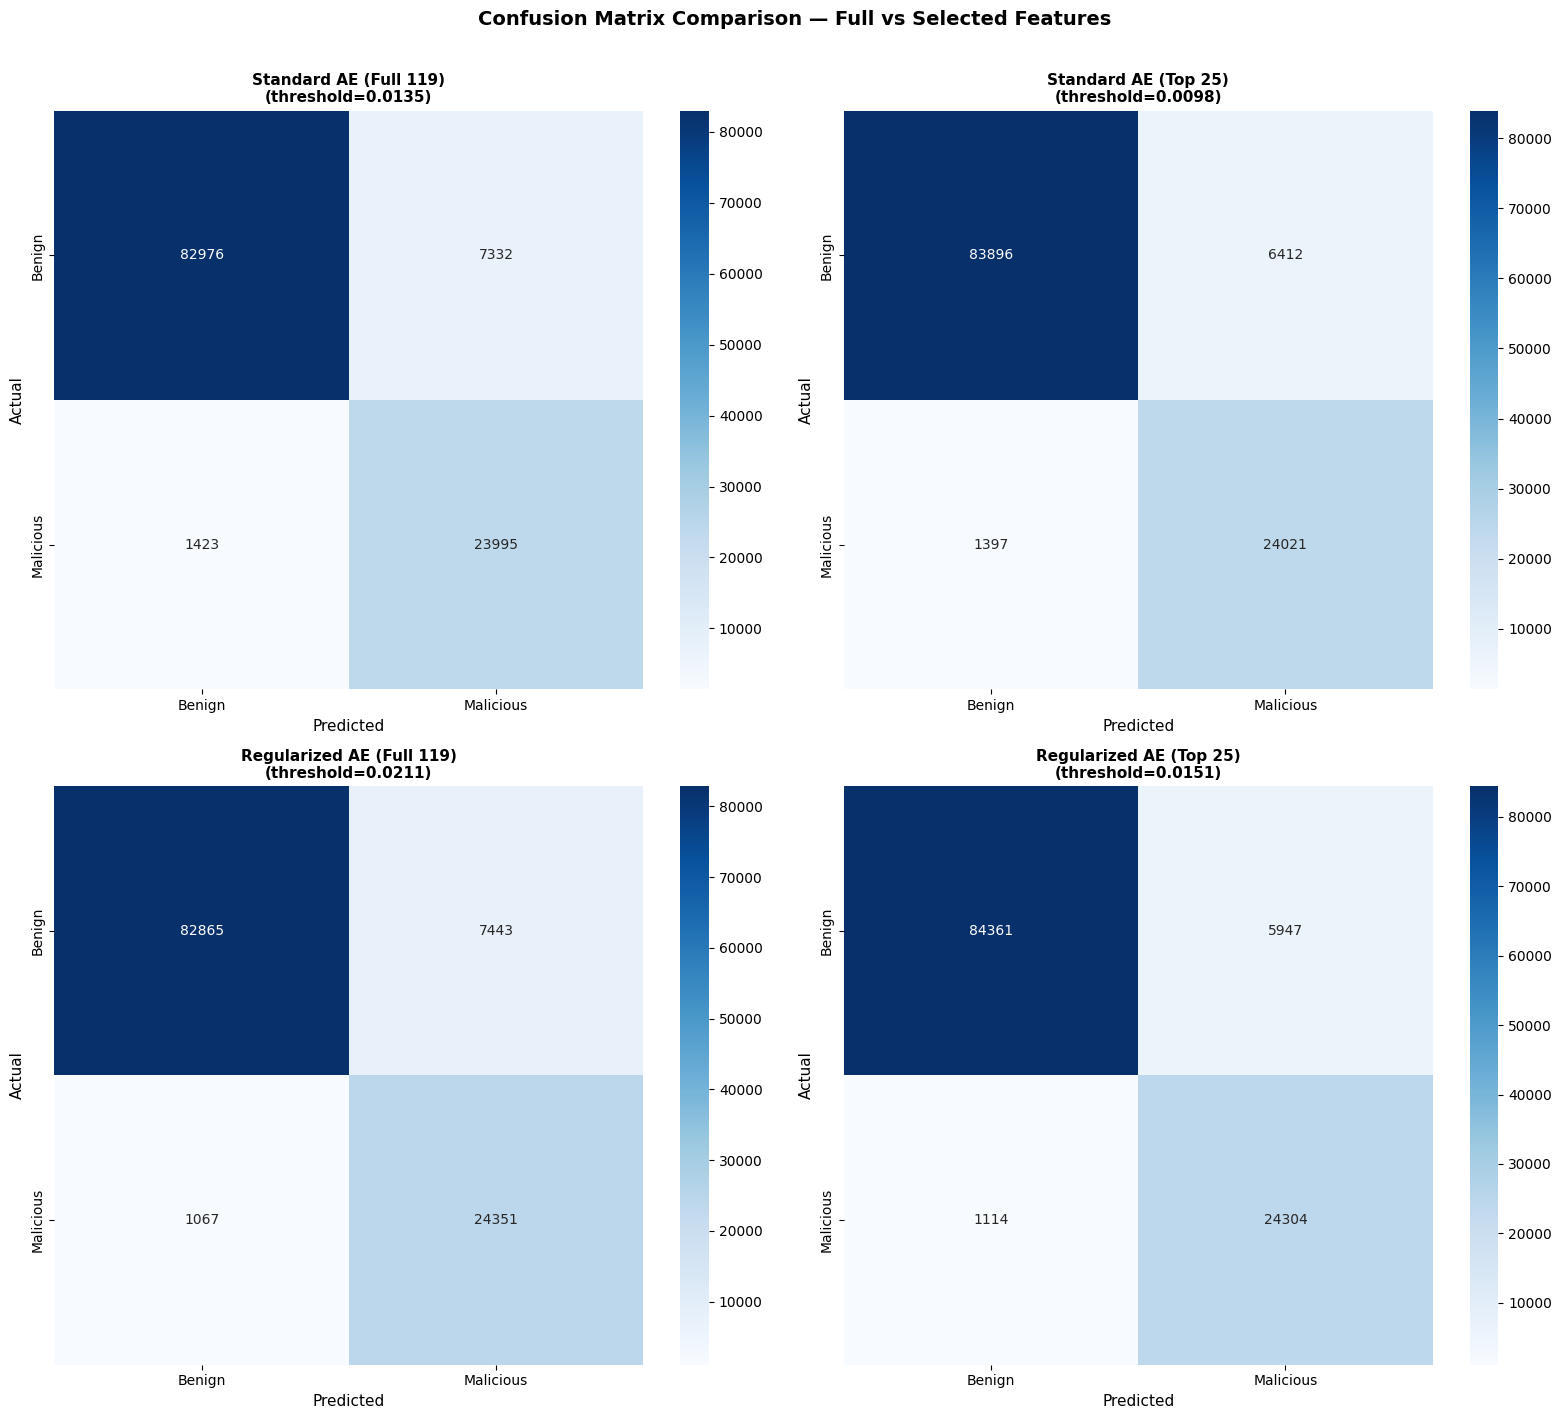

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

all_thresholds = [th_ae_full, th_ae_reduced, th_reg_full, th_reg_reduced]

for idx, (name, scores, th) in enumerate(zip(labels_names, all_scores, all_thresholds)):
    preds = (scores > th).astype(int)
    cm = confusion_matrix(y_malicious, preds)
    row, col = idx // 2, idx % 2
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[row][col],
                xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
    axes[row][col].set_xlabel('Predicted', fontsize=11)
    axes[row][col].set_ylabel('Actual', fontsize=11)
    axes[row][col].set_title(f'{name}\n(threshold={th:.4f})', fontsize=11, fontweight='bold')

plt.suptitle('Confusion Matrix Comparison — Full vs Selected Features', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('autoencoder_outputs/feature_selection_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 14: Reconstruction Error Distribution

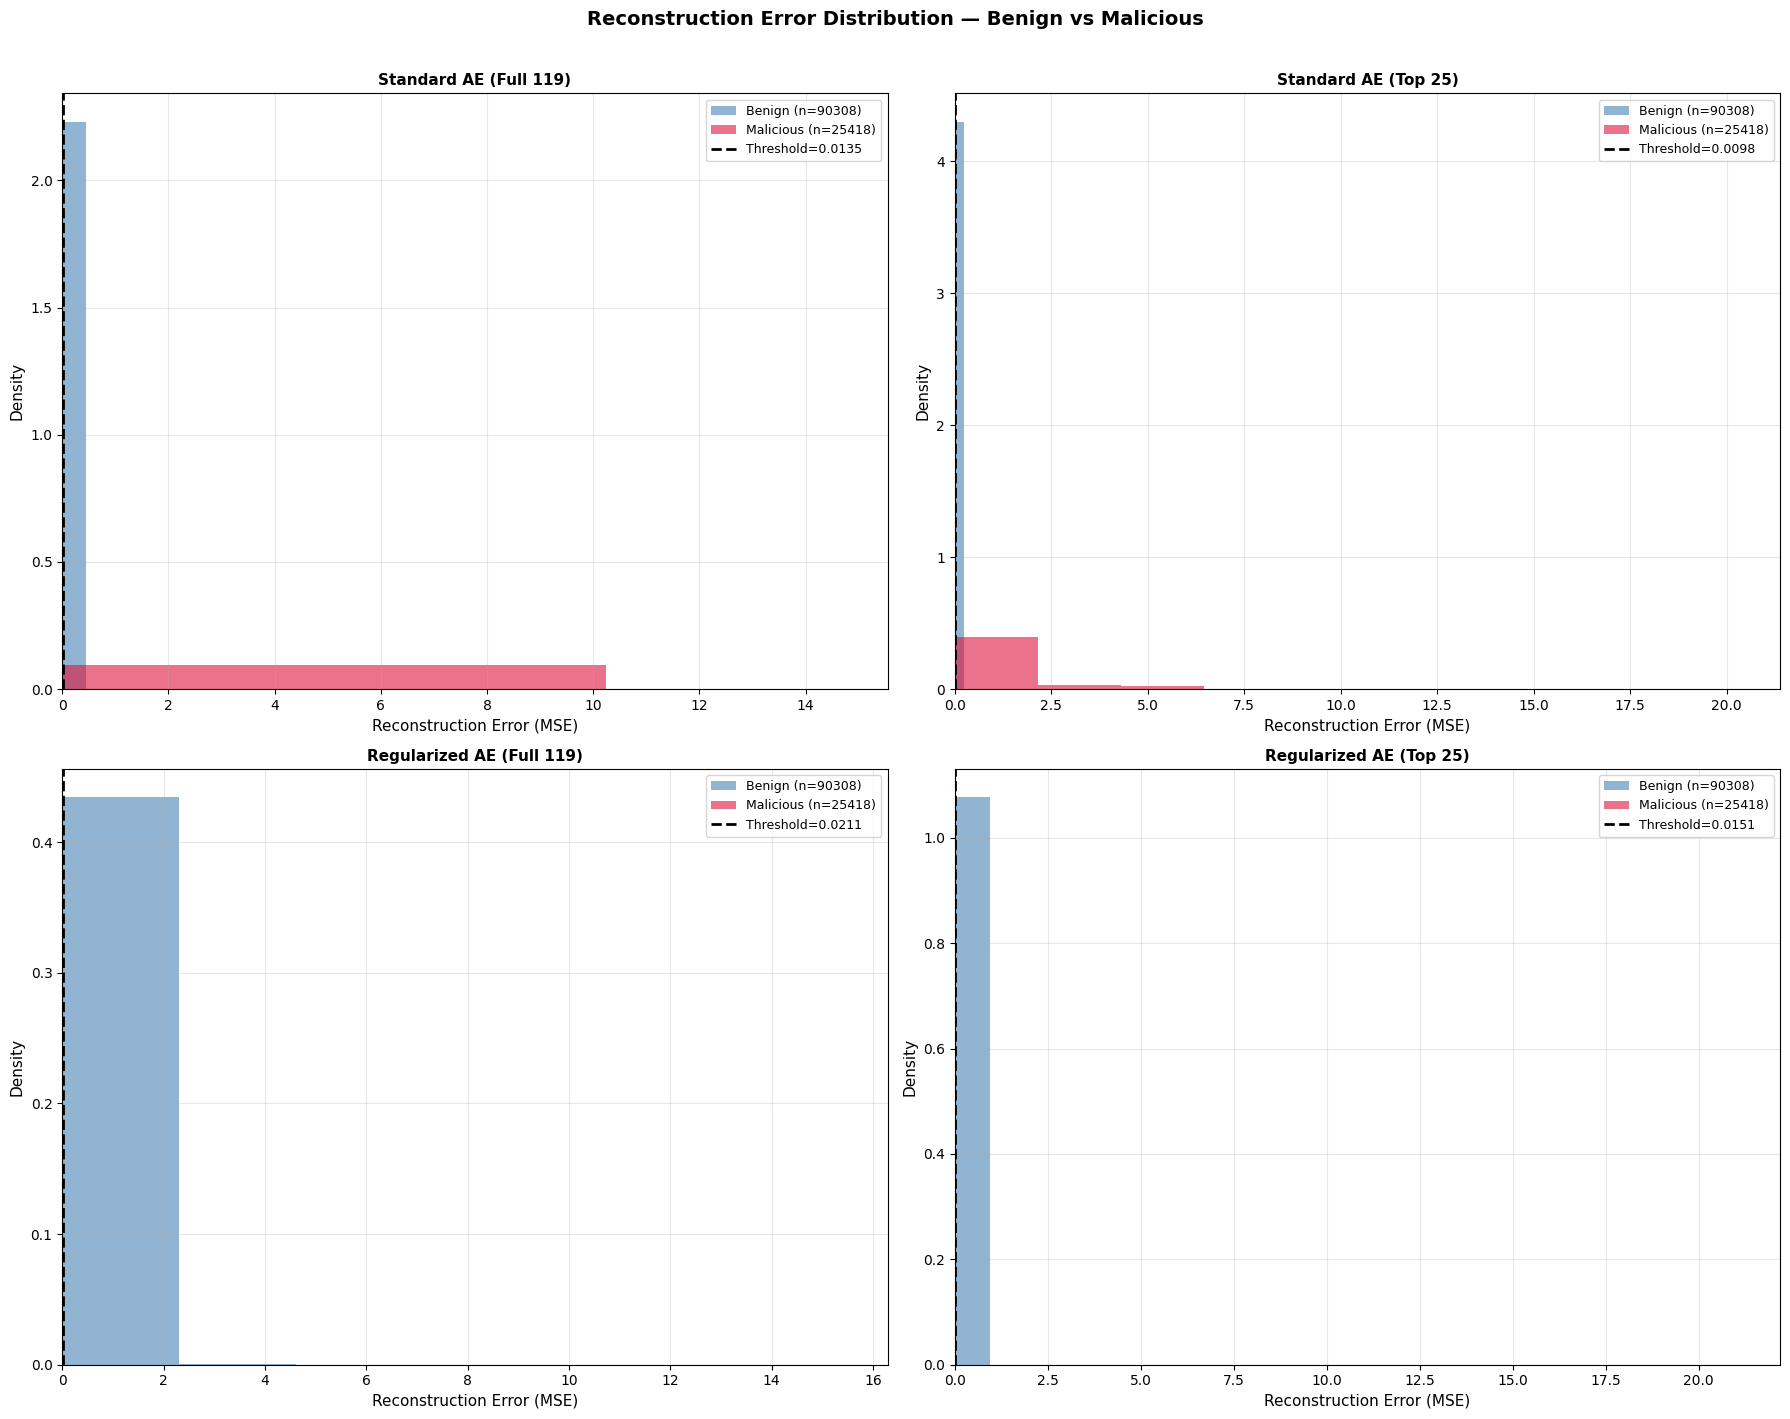

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

for idx, (name, scores) in enumerate(zip(labels_names, all_scores)):
    row, col = idx // 2, idx % 2
    ax = axes[row][col]
    
    benign_scores = scores[y_malicious == 0]
    malicious_scores = scores[y_malicious == 1]
    
    ax.hist(benign_scores, bins=100, alpha=0.6, color='steelblue', label=f'Benign (n={len(benign_scores)})', density=True)
    ax.hist(malicious_scores, bins=100, alpha=0.6, color='crimson', label=f'Malicious (n={len(malicious_scores)})', density=True)
    
    ax.axvline(x=all_thresholds[idx], color='black', linestyle='--', linewidth=2, label=f'Threshold={all_thresholds[idx]:.4f}')
    ax.set_xlabel('Reconstruction Error (MSE)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(f'{name}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_xlim(0, np.percentile(scores, 99.5))
    ax.grid(True, alpha=0.3)

plt.suptitle('Reconstruction Error Distribution — Benign vs Malicious', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('autoencoder_outputs/feature_selection_error_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 15: t-SNE Latent Space Visualization

Latent vectors shape — Full: (5000, 64), Reduced: (5000, 64)


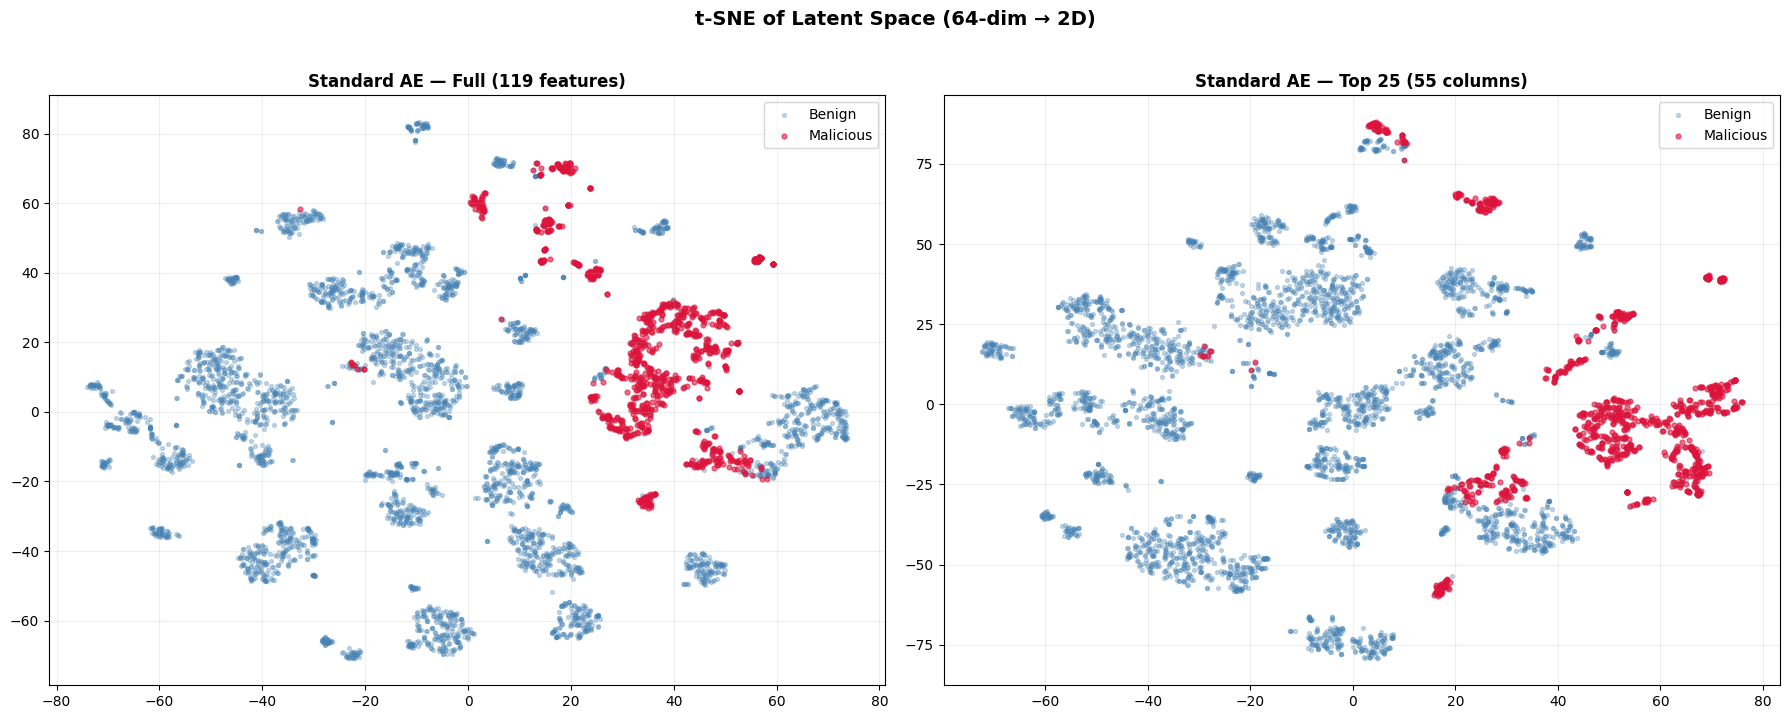

In [17]:
from sklearn.manifold import TSNE

# Extract latent representations from the best Standard AE models
def get_latent_vectors(model, data_tensor):
    model.eval()
    with torch.no_grad():
        x = data_tensor
        for layer in model.encoder:
            x = layer(x)
    return x.numpy()

# Use a subsample for t-SNE (too slow on full dataset)
np.random.seed(42)
n_subsample = 5000
sub_idx = np.random.choice(len(X_full_scaled), n_subsample, replace=False)

X_full_sub = torch.FloatTensor(X_full_scaled[sub_idx])
X_reduced_sub = torch.FloatTensor(X_reduced_scaled[sub_idx])
y_sub = y_malicious[sub_idx]

latent_full = get_latent_vectors(model_ae_full, X_full_sub)
latent_reduced = get_latent_vectors(model_ae_reduced, X_reduced_sub)

print(f"Latent vectors shape — Full: {latent_full.shape}, Reduced: {latent_reduced.shape}")

# t-SNE
tsne_full = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_reduced = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)

emb_full = tsne_full.fit_transform(latent_full)
emb_reduced = tsne_reduced.fit_transform(latent_reduced)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, emb, title in zip(axes, [emb_full, emb_reduced], 
                           ['Standard AE — Full (119 features)', 'Standard AE — Top 25 (55 columns)']):
    benign_mask = y_sub == 0
    malicious_mask = y_sub == 1
    ax.scatter(emb[benign_mask, 0], emb[benign_mask, 1], c='steelblue', alpha=0.3, s=8, label='Benign')
    ax.scatter(emb[malicious_mask, 0], emb[malicious_mask, 1], c='crimson', alpha=0.6, s=12, label='Malicious')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.2)

plt.suptitle('t-SNE of Latent Space (64-dim → 2D)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('autoencoder_outputs/feature_selection_tsne_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 16: Save Models & Results

In [18]:
import json

output_dir = 'autoencoder_outputs'

# Save models
torch.save(model_ae_full.state_dict(), f'{output_dir}/ae_full_features.pth')
torch.save(model_ae_reduced.state_dict(), f'{output_dir}/ae_top25_features.pth')
torch.save(model_reg_full.state_dict(), f'{output_dir}/reg_ae_full_features.pth')
torch.save(model_reg_reduced.state_dict(), f'{output_dir}/reg_ae_top25_features.pth')

# Save comparison results
comparison_df = pd.DataFrame(all_results).T
comparison_df.to_csv(f'{output_dir}/feature_selection_comparison.csv')

# Save selected features list
feature_info = {
    'n_conceptual_features': 25,
    'n_actual_columns': len(selected_columns),
    'log_secbert_dims': len(log_secbert_cols),
    'cmd_secbert_dims': len(cmd_secbert_cols),
    'n_individual_features': len(top_individual_features),
    'individual_features': top_individual_features,
    'all_selected_columns': selected_columns
}
with open(f'{output_dir}/selected_features_top25.json', 'w') as f:
    json.dump(feature_info, f, indent=2)

# Save latent vectors
latent_full_all = get_latent_vectors(model_ae_full, torch.FloatTensor(X_full_scaled))
latent_reduced_all = get_latent_vectors(model_ae_reduced, torch.FloatTensor(X_reduced_scaled))
np.save(f'{output_dir}/latent_ae_full_features.npy', latent_full_all)
np.save(f'{output_dir}/latent_ae_top25_features.npy', latent_reduced_all)

print("All models, results, and latent vectors saved!")
print(f"\nFiles saved to '{output_dir}/':")
for f in ['ae_full_features.pth', 'ae_top25_features.pth', 'reg_ae_full_features.pth', 
          'reg_ae_top25_features.pth', 'feature_selection_comparison.csv',
          'selected_features_top25.json', 'latent_ae_full_features.npy', 'latent_ae_top25_features.npy']:
    print(f"  ✓ {f}")

All models, results, and latent vectors saved!

Files saved to 'autoencoder_outputs/':
  ✓ ae_full_features.pth
  ✓ ae_top25_features.pth
  ✓ reg_ae_full_features.pth
  ✓ reg_ae_top25_features.pth
  ✓ feature_selection_comparison.csv
  ✓ selected_features_top25.json
  ✓ latent_ae_full_features.npy
  ✓ latent_ae_top25_features.npy


## Part 17: Final Summary & Recommendation

### Experiment Recap
- **Objective:** Determine if reducing from **119 features** to the **top 25 conceptual features** (55 actual columns) improves autoencoder-based APT anomaly detection
- **Method:** Trained 4 models (Standard AE + Regularized AE × Full vs Reduced features), benign-only training
- **Top 25 features** selected via ensemble importance (RF, XGB, LightGBM, Permutation, Mutual Information, F-Score)
- **Feature groups:** 16 log_secbert_emb dims + 16 cmd_secbert_emb dims + 23 individual features

### Key Metrics Compared
| Metric | What it measures |
|--------|-----------------|
| ROC-AUC | Overall ranking quality |
| F1-Score | Balance of precision and recall |
| Balanced Accuracy | Accounts for class imbalance |
| Average Precision | Area under PR curve |

In [21]:
# Final comparison summary
print("=" * 80)
print("FINAL COMPARISON: Feature Selection Impact on Autoencoder Anomaly Detection")
print("=" * 80)

comp_df = pd.DataFrame(all_results).T
print(f"\n{'Model':<35} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10} {'Precision':>10} {'Recall':>10}")
print("-" * 85)
for name, row in comp_df.iterrows():
    print(f"{name:<35} {row['ROC-AUC']:>10.4f} {row['F1']:>10.4f} {row['Balanced Acc']:>10.4f} {row['Precision']:>10.4f} {row['Recall']:>10.4f}")

print("\n" + "=" * 80)
print("DELTAS (Reduced - Full):")
print("=" * 80)

# Standard AE delta
ae_full = comp_df.loc['Standard AE (Full 119)']
ae_red = comp_df.loc['Standard AE (Top 25)']
print(f"\n{'Standard AE:':<25}")
for metric in ['ROC-AUC', 'F1', 'Balanced Acc', 'Precision', 'Recall']:
    delta = ae_red[metric] - ae_full[metric]
    sign = '+' if delta >= 0 else ''
    symbol = '✓ IMPROVED' if delta > 0 else ('= SAME' if delta == 0 else '✗ DECREASED')
    print(f"  {metric:<20} {sign}{delta:.4f}  {symbol}")

# Regularized AE delta
reg_full = comp_df.loc['Regularized AE (Full 119)']
reg_red = comp_df.loc['Regularized AE (Top 25)']
print(f"\n{'Regularized AE:':<25}")
for metric in ['ROC-AUC', 'F1', 'Balanced Acc', 'Precision', 'Recall']:
    delta = reg_red[metric] - reg_full[metric]
    sign = '+' if delta >= 0 else ''
    symbol = '✓ IMPROVED' if delta > 0 else ('= SAME' if delta == 0 else '✗ DECREASED')
    print(f"  {metric:<20} {sign}{delta:.4f}  {symbol}")

# Overall best model
print("\n" + "=" * 80)
best_model = comp_df['ROC-AUC'].idxmax()
best_auc = comp_df['ROC-AUC'].max()
print(f"BEST MODEL: {best_model}")
print(f"Best ROC-AUC: {best_auc:.4f}")
print(f"\nFeature reduction: 119 → 55 columns ({(1 - 55/119)*100:.1f}% reduction)")
print(f"Conceptual features: 119 individual → 25 grouped features")
print("=" * 80)

FINAL COMPARISON: Feature Selection Impact on Autoencoder Anomaly Detection

Model                                  ROC-AUC         F1    Bal.Acc  Precision     Recall
-------------------------------------------------------------------------------------
Standard AE (Full 119)                  0.9752     0.8457     0.9314     0.7660     0.9440
Standard AE (Top 25)                    0.9821     0.8602     0.9370     0.7893     0.9450
Regularized AE (Full 119)               0.9773     0.8513     0.9378     0.7659     0.9580
Regularized AE (Top 25)                 0.9849     0.8732     0.9452     0.8034     0.9562

DELTAS (Reduced - Full):

Standard AE:             
  ROC-AUC              +0.0069  ✓ IMPROVED
  F1                   +0.0145  ✓ IMPROVED
  Balanced Acc         +0.0056  ✓ IMPROVED
  Precision            +0.0234  ✓ IMPROVED
  Recall               +0.0010  ✓ IMPROVED

Regularized AE:          
  ROC-AUC              +0.0076  ✓ IMPROVED
  F1                   +0.0219  ✓ IMPROVED
 

In [23]:
# Verify NO data leakage columns are present
leakage_keywords = ['rule_level', 'rule.level', 'rule_id', 'rule.id', 
                     'mitre', 'MITRE', 'ckc', 'cyber_kill_chain',
                     'rule.mitre', 'rule_mitre']

all_cols = list(X_full_df.columns)
print("=" * 70)
print("DATA LEAKAGE VERIFICATION")
print("=" * 70)
print(f"\nFile used: feature_selection_outputs2/feature_matrix_no_leakage.parquet")
print(f"Total columns: {len(all_cols)}")

found_leakage = []
for col in all_cols:
    for kw in leakage_keywords:
        if kw.lower() in col.lower():
            found_leakage.append(col)
            break

if found_leakage:
    print(f"\n⚠️ WARNING: Found {len(found_leakage)} potential leakage columns:")
    for c in found_leakage:
        print(f"  - {c}")
else:
    print("\n✅ NO leakage columns found! Confirmed safe.")
    print("   ✓ No rule.level / rule_level")
    print("   ✓ No rule.id / rule_id")  
    print("   ✓ No MITRE ATT&CK columns")
    print("   ✓ No CKC / cyber_kill_chain columns")

print(f"\nLabels (separate file, NOT features): {list(labels_df.columns)}")
print("   → malicious, ckc used only as Y targets, never as input features")

DATA LEAKAGE VERIFICATION

File used: feature_selection_outputs2/feature_matrix_no_leakage.parquet
Total columns: 119

✅ NO leakage columns found! Confirmed safe.
   ✓ No rule.level / rule_level
   ✓ No rule.id / rule_id
   ✓ No MITRE ATT&CK columns
   ✓ No CKC / cyber_kill_chain columns

Labels (separate file, NOT features): ['malicious', 'cyber_kill_chain_tactic', 'ckc_encoded']
   → malicious, ckc used only as Y targets, never as input features
